# Feature Engineering

In [1]:
%load_ext watermark
%watermark

Last updated: 2022-08-30T23:25:25.506406-05:00

Python implementation: CPython
Python version       : 3.7.4
IPython version      : 7.8.0

Compiler    : MSC v.1915 64 bit (AMD64)
OS          : Windows
Release     : 10
Machine     : AMD64
Processor   : Intel64 Family 6 Model 158 Stepping 9, GenuineIntel
CPU cores   : 8
Architecture: 64bit



# Objetivos:

- Eliminar características no deseadas
- Manejar valores faltantes
- Manejar características categóricas
- Manejar la escala de características
- Eliminar valores atípicos

In [3]:
import pandas as pd
%matplotlib inline 
# no crea widget ni nada para no presentar resultados.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = (12,12) # 10 pulgadas de ancho y 10 de alto para todos los plots


In [4]:
bank_dp = pd.read_parquet("../output/data-bank_1.parquet",engine='pyarrow')

In [5]:
bank_dp.head(5)

,edad,trabajo,estadoCivil,educacion,flag_mora,prom_saldoAnual,flag_hipotecario,flag_prestamo,tipo_contacto,dia_UltContacto,mes_UltContacto,seg_UltContacto,cant_contactoCampanha,cantDias_AfterUltContacto,cant_contactoBeforeCampanha,result_campanha,FlagTarget_DP
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [8]:
bank_dp.shape[0]

11162

## Agrupación de datos

Para facilitar el entendimiento de los datos en el análisis bi y multivariable, se establece un rango para el campo edad.

In [6]:
bins = [18, 21, 26, 31, 36, 41, 46, 51, 56, 61, 66, 71, 76]
names = ['18-20', '21-25', '26-30', '31-35', '36-40', \
            '41-45', '46-50', '51-55', '55-60', '61-65', '66-70', '71-75', '76+']

d = dict(enumerate(names, 1))
bank_dp['Rango_edad'] = np.vectorize(d.get)(np.digitize(bank_dp['edad'],bins))

Conclusion:
- Distribución en % de los valores por rango de edad, con un 21% las personas entre 31 y 35 años han participado en más campañas de Depósito a Plazo

In [7]:
bank_dp.Rango_edad.value_counts(normalize=True)

31-35    0.211790
36-40    0.163412
26-30    0.139491
41-45    0.119513
46-50    0.104103
51-55    0.088425
55-60    0.078212
21-25    0.036642
61-65    0.019083
76+      0.013707
66-70    0.011199
71-75    0.010751
18-20    0.003673
Name: Rango_edad, dtype: float64

## Corrección y evaluación de datos

### outliers

#### a) Edad

Examinamos la distribución de edad visualmente como un diagrama de caja y, aunque tiene una distribución normal, está sesgada hacia la derecha.

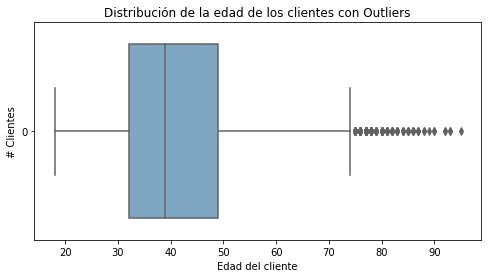

The first quartile is 32.0. 
The third quartile is 49.0. 
The IQR is 17.0.
The mean is 41.23.
The standard deviation is 11.91.
The median is 39.0.


In [9]:
# Boxplot of age as another way of showing distribution
fig = plt.figure(figsize = (8,4))
plt.title ('Distribución de la edad de los clientes con Outliers')
plt.xlabel('Edad del cliente')
plt.ylabel('# Clientes')

sns.boxplot(data=bank_dp['edad'], palette="PuBu", orient='h')
plt.show()

# Computing IQR
Q1 = bank_dp['edad'].quantile(0.25)
Q3 = bank_dp['edad'].quantile(0.75)
IQR = Q3-Q1

# Computing Summary Statistics
mean_1 = round(bank_dp['edad'].mean(),2)
std_1 = round(bank_dp['edad'].std(),2)
median_1 = round(bank_dp['edad'].median(),2)
print('The first quartile is %s. '%Q1)
print('The third quartile is %s. '%Q3)
print('The IQR is %s.'%IQR)
print('The mean is %s.'%mean_1)
print('The standard deviation is %s.'%std_1)
print('The median is %s.'%median_1)

In [10]:
lower_bound = Q1-(1.5*IQR)
upper_bound = Q3+(1.5*IQR)

outliers_eurobank2 = bank_dp.loc[(bank_dp['edad'] < lower_bound) | (bank_dp['edad'] > upper_bound)]
average_age = round(bank_dp.edad.mean(), 2)
print('La edad promedio del data frame original es %s.' % average_age)

average_age_outliers_eurobank2 = round(outliers_eurobank2.edad.mean(),2)
print('La edad promedio de los outliers es %s.' % average_age_outliers_eurobank2)

La edad promedio del data frame original es 41.23.
La edad promedio de los outliers es 79.7.


In [9]:
#justificacion xq no eliminar los campos outliers

En este análisis, aunque generalmente estamos interesados en datos sensibles a los valores atípicos, estamos igualmente interesados en examinar el conjunto de datos que es resistente a estos valores atípicos como base de comparación, en el siguiente gráfico de manera demostrativa se ha eliminado los outliers

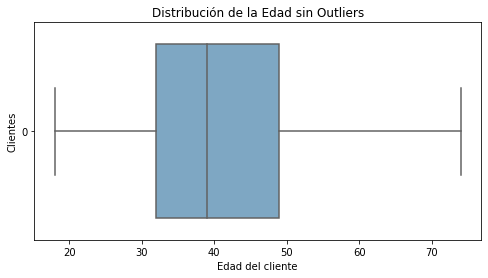

In [11]:
# Boxplot of age without outliers as another way of showing distribution
fig = plt.figure(figsize = (8,4))
plt.title ('Distribución de la Edad sin Outliers')
plt.xlabel('Edad del cliente')
plt.ylabel('Clientes')
sns.boxplot(data=bank_dp['edad'], palette="PuBu", orient='h', showfliers = False)
plt.show()

filter = (bank_dp['edad'] >= Q1 - 1.5 * IQR) & (bank_dp['edad'] <= Q3 + 1.5 *IQR)

La eliminación de los valores atípicos de la variable de edad arroja poca importancia observable, como se muestra a continuación. Por ejemplo:

In [12]:
# Computing Means, Standard Deviations, and Observing Differences
mean_2 = round(bank_dp.loc[filter]['edad'].mean(),2)
mean_difference = round((mean_1 - mean_2),2)
std_2 = round(bank_dp.loc[filter]['edad'].std(),2)
std_difference = round((std_1 - std_2),2)
median_2 = round(bank_dp.loc[filter]['edad'].median(),2)
median_difference = round((median_1 - median_2),2)

print('La edad promedio sin outliers es %s.'%mean_2)
print('La desviación estándar de la edad variable sin outliers %s.'%std_2)
print('La mediana de la edad sin outliers es %s.'%median_2)

print("\n")

print('La diferencia entre el promedio con outliers y el promedio \
sin outliers es %s.'%mean_difference)
print('La diferencia entre la desviación estándar con \
outliers y la desviación estándar sin outliers es %s.'%std_difference)
print('La diferencia entre la mediana con \
outliers y la mediana sin outliers es %s.'%median_difference)


La edad promedio sin outliers es 40.63.
La desviación estándar de la edad variable sin outliers 10.98.
La mediana de la edad sin outliers es 38.0.


La diferencia entre el promedio con outliers y el promedio sin outliers es 0.6.
La diferencia entre la desviación estándar con outliers y la desviación estándar sin outliers es 0.93.
La diferencia entre la mediana con outliers y la mediana sin outliers es 1.0.


#### b) prom_saldoAnual: saldo medio anual, en euros

En la siguiente grafica vemos que los datos negativos y cercanos a 0 tienen una alta participación 39587 clientes

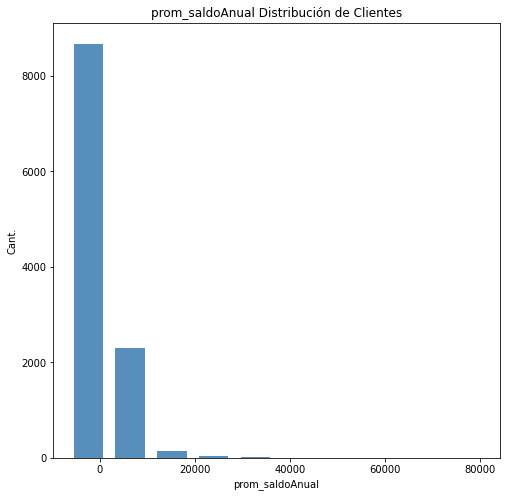

Los siguientes valores representan el número de puntos de datos entre cada rectangulo:
[8673 2296  136   37   12    1    3    1    1    2]


In [13]:
# Plotting a histogram to show distribution
fig = plt.figure(figsize = (8,8))
plt.hist(bank_dp['prom_saldoAnual'], bins=10, color='steelblue', alpha=0.9, rwidth=0.7)
plt.title ('prom_saldoAnual Distribución de Clientes')
plt.xlabel('prom_saldoAnual') 
plt.ylabel('Cant.')
plt.show()

print('Los siguientes valores representan el número de puntos de datos entre cada rectangulo:')

counts, bin_edges = np.histogram(bank_dp['prom_saldoAnual'], bins=10)
print(counts)

Estos valores atípicos no deben eliminarse ya que a saldos promedios altos, el cliente muestra interés en el depósito.

In [14]:
bank_dp.groupby(['FlagTarget_DP','prom_saldoAnual'],sort=True)['prom_saldoAnual'].count()

FlagTarget_DP  prom_saldoAnual
no             -6847              1
               -2712              1
               -2282              1
               -2049              1
               -1965              1
                                 ..
yes             34646             1
                36252             1
                45248             1
                52587             2
                81204             2
Name: prom_saldoAnual, Length: 5082, dtype: int64

#### c) seg_UltContacto: Duración del último contacto, en segundos (numérico)

Estos valores atípicos no deben eliminarse a medida que aumenta la duración, el cliente muestra interés en el depósito

In [15]:
# remove outliers in feature duration...
bank_dp.groupby(['FlagTarget_DP','seg_UltContacto'],sort=True)['seg_UltContacto'].count()

FlagTarget_DP  seg_UltContacto
no             2                  1
               3                  1
               4                  2
               5                  4
               6                  6
                                 ..
yes            3094               1
               3102               1
               3183               1
               3253               1
               3881               1
Name: seg_UltContacto, Length: 2157, dtype: int64

#### d) cant_contactoCampanha: Número de contactos realizados durante esta campaña y para este cliente (incluye el último contacto)

In [16]:
bank_dp.groupby(['FlagTarget_DP','cant_contactoCampanha'],sort=True)['cant_contactoCampanha'].count()

FlagTarget_DP  cant_contactoCampanha
no             1                        2237
               2                        1627
               3                         703
               4                         454
               5                         239
               6                         173
               7                          92
               8                          96
               9                          51
               10                         38
               11                         24
               12                         25
               13                         24
               14                         11
               15                          9
               16                          7
               17                          8
               18                          8
               19                          5
               20                          4
               21                          7
               22 

In [17]:
df_aux= bank_dp[['FlagTarget_DP','cant_contactoCampanha']][bank_dp['cant_contactoCampanha'] >= 33]
print('Cantidad de registros a eliminar: %s.'%df_aux.count())
print('Valores del únicos ´FlagTarget_DP´ a eliminar: %s.'%df_aux['FlagTarget_DP'].unique())
#omitir tesis
#cant_contactoCampanha    38
#dtype: int64.

Cantidad de registros a eliminar: FlagTarget_DP            5
cant_contactoCampanha    5
dtype: int64.
Valores del únicos ´FlagTarget_DP´ a eliminar: ['no'].


Eliminar las filas cuyo cant_contactoCampanha sea > 32, debido a qué los 38 registros listados no contienen algún caso de adquisción del depósito "yes", como una medida de balanceo de datos se excluiría ya que no aporta valor al objetivo que es predecir las personas que tienen valor "yes" adquieren el Depósito a Plazo.

Según el comportamiento del Dataset las personas cuya cantidad de contacto en campaña `cant_contactoCampanha` supere los 32, ya NO adquieren un DP. 

In [18]:
bank_dp_2 = bank_dp[bank_dp['cant_contactoCampanha'] < 33]

#### e) cantDias_AfterUltContacto

In [20]:
#no va tesis
Cant_RegDS = bank_dp_2.shape[0]
Cant_RegDS

11157

In [25]:
#no va tesis
(Cant_RegDS-3384)/bank_dp_2.shape[0]

0.6966926593170207

In [23]:
3384/Cant_RegDS

0.3033073406829793

In [29]:
len (bank_dp_2[bank_dp_2['cantDias_AfterUltContacto'] > 400] ) / len(bank_dp_2) * 100

1.2010397060141615

`cant_contactoCampanha` contiene la cantidad de días que transcurrieron después de que se contactó al cliente por última vez desde una campaña anterior.
- solo el 1,2% de los valores por encima de 400. Posiblemente sean valores atípicos, por lo que deberíamos considerar imputar algo (posiblemente el valor medio) en lugar de estos valores.
- "-1" posiblemente significa que el cliente no fue contactado antes o significa que faltan datos.

In [31]:
bank_dp.cantDias_AfterUltContacto.value_counts(normalize=True)

-1      0.745744
 92     0.009497
 182    0.007973
 91     0.007526
 181    0.007257
          ...   
 437    0.000090
 728    0.000090
 518    0.000090
 828    0.000090
 118    0.000090
Name: cantDias_AfterUltContacto, Length: 472, dtype: float64

El  "-1" representa el `74.5%` del data set se procederá a eliminar esta columna, no aportará significativamente al Modelo de Machine Learning

In [34]:
bank_dp_2.drop(['cantDias_AfterUltContacto'],axis=1, inplace=True)

D:\ProgramData\Anaconda3\envs\EnvDataLab\lib\site-packages\pandas\core\frame.py:4913: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  errors=errors,


In [37]:
print("Existían 18 columnas hasta el momento ahora solo quedan {}, se ha eliminado la columna `cantDias_AfterUltContacto`".format(bank_dp_2.shape[1]))

Existían 18 columnas hasta el momento ahora solo quedan 17, se ha eliminado la columna `cantDias_AfterUltContacto`


#### f) cant_contactoBeforeCampanha

`cant_contactoBeforeCampanha` contiene la cantidad de contactos realizados durante esta campaña y para este cliente (numérico, incluye el último contacto) Los números de 'campaña' por encima de 34 son claramente falsos, por lo que se sugiere imputarlos con valores de campaña promedio durante la limpieza de datos.

In [41]:
#No va tesis
bank_dp_2.groupby(['FlagTarget_DP','cant_contactoBeforeCampanha'],sort=True)['cant_contactoBeforeCampanha'].count()

FlagTarget_DP  cant_contactoBeforeCampanha
no             0                              4935
               1                               304
               2                               237
               3                               141
               4                                73
               5                                44
               6                                34
               7                                23
               8                                21
               9                                10
               10                                4
               11                                8
               12                                6
               13                                2
               14                                1
               15                                4
               16                                2
               17                                8
               18                      

Al eliminarse los que son mayores a 34 contactos en campaña, se sólo perderá el 4.39%  del dataset

In [39]:
len(bank_dp_2[bank_dp_2['cant_contactoBeforeCampanha'] > 34] ) / len(bank_dp_2) * 100

0.04481491440351349

In [42]:
bank_dp_3 = bank_dp_2[bank_dp_2['cant_contactoBeforeCampanha'] < 34]

In [43]:
print("Ahora quedan {} registros en total del data set".format(bank_dp_3.shape[0]))

Ahora quedan 11152 registros en total del data set


In [44]:
#EXPORT PARQUET
path="../output/"
bank_dp_3.to_parquet(path+"data-bank_2_FE.parquet",engine="pyarrow")

In [30]:
#EDA: edad(EurobankDataset), en otro notebook

4.3999999999999995